<!-- d2l:prose id=sh-async-md-1 fw=all -->

# Asynchronous Successive Halving

As we have seen in that section, we can accelerate HPO by
distributing the evaluation of hyperparameter configurations across either
multiple instances or multiple CPUs / GPUs on a single instance. However,
compared to random search, it is not straightforward to run
successive halving (SH) asynchronously in a distributed setting. Before we can
decide which configuration to run next, we first have to collect all
observations at the current rung level. This requires to
synchronize workers at each rung level. For example, for the lowest rung level
$r_{\mathrm{min}}$, we first have to evaluate all $N = \eta^K$ configurations, before we
can promote the $\frac{1}{\eta}$ of them to the next rung level.

In any distributed system, synchronization typically implies idle time for workers.
First, we often observe high variations in training time across hyperparameter
configurations. For example, assuming the number of filters per layer is a
hyperparameter, then networks with less filters finish training faster than
networks with more filters, which implies idle worker time due to stragglers.
Moreover, the number of slots in a rung level is not always a multiple of the number
of workers, in which case some workers may even sit idle for a full batch.

Figure the figure shows the scheduling of synchronous SH with $\eta=2$
for four different trials with two workers. We start with evaluating Trial-0 and
Trial-1 for one epoch and immediately continue with the next two trials once they
are finished. We first have to wait until Trial-2 finishes, which takes
substantially more time than the other trials, before we can promote the best two
trials, i.e., Trial-0 and Trial-3 to the next rung level. This causes idle time for
Worker-1. Then, we continue with Rung 1. Also, here Trial-3 takes longer than Trial-0,
which leads to an additional idling time of Worker-0. Once we reach Rung-2, only
the best trial, Trial-0, remains which occupies only one worker. To avoid that
Worker-1 idles during that time, most implementations of SH continue already with
the next round, and start evaluating new trials (e.g Trial-4) on the first rung.

![Synchronous successive halving with two workers.](../img/sync_sh.svg)

Asynchronous successive halving (ASHA) [@li-arxiv18] adapts SH to the asynchronous
parallel scenario. The main idea of ASHA is to promote configurations to the next rung
level as soon as we collected at least $\eta$ observations on the current rung level.
This decision rule may lead to suboptimal promotions: configurations can be promoted to the
next rung level, which in hindsight do not compare favourably against most others
at the same rung level. On the other hand, we get rid of all synchronization points
this way. In practice, such suboptimal initial promotions have only a modest impact on
performance, not only because the ranking of hyperparameter configurations is often
fairly consistent across rung levels, but also because rungs grow over time and
reflect the distribution of metric values at this level better and better. If a
worker is free, but no configuration can be promoted, we start a new configuration
with $r = r_{\mathrm{min}}$, i.e the first rung level.

the figure shows the scheduling of the same configurations for ASHA. Once Trial-1
finishes, we collect the results of two trials (i.e Trial-0 and Trial-1) and
immediately promote the better of them (Trial-0) to the next rung level. After Trial-0
finishes on rung 1, there are too few trials there in order to support a further
promotion. Hence, we continue with rung 0 and evaluate Trial-3. Once Trial-3 finishes,
Trial-2 is still pending. At this point we have 3 trials evaluated on rung 0 and one
trial evaluated already on rung 1. Since Trial-3 performs worse than Trial-0 at rung 0,
and $\eta=2$, we cannot promote any new trial yet, and Worker-1 starts Trial-4 from
scratch instead. However, once Trial-2 finishes and
scores worse than Trial-3, the latter is promoted towards rung 1. Afterwards, we
collected 2 evaluations on rung 1, which means we can now promote Trial-0 towards
rung 2. At the same time, Worker-1 continues with evaluating new trials (i.e.,
Trial-5) on rung 0.


![Asynchronous successive halving (ASHA) with two workers.](../img/asha.svg)

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import contextlib
import io
import logging
import matplotlib.pyplot as plt

In [3]:
# Use INFO level so the periodic Syne Tune tuning-status table appears,
# but use a clean format that drops the "INFO:syne_tune.tuner:" prefix.
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
# Silence Syne Tune's import-time chatter about optional AWS dependencies
# (sagemaker, s3fs) and Ray Tune. We use the local PythonBackend, so those
# are not needed. Suppress both print() and logging.info() during imports.
_root = logging.getLogger()
_prev_level = _root.level
_root.setLevel(logging.WARNING)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        from syne_tune.config_space import loguniform, randint
        from syne_tune.backend.python_backend.python_backend import PythonBackend
        from syne_tune.optimizer.baselines import ASHA
        from syne_tune import Tuner, StoppingCriterion
        from syne_tune.experiments import load_experiment
finally:
    _root.setLevel(_prev_level)

# Silence the per-trial subprocess-command spam from local_backend and
# drop the per-trial scheduling / completion lines from the tuner logger.
# Keep the periodic "tuning status (last metric is reported)" updates so
# the reader can still see progress over time.
class _DropPerTrialNoise(logging.Filter):
    _DROP = (
        "results of trials will be saved",
        "scheduled ",
        "Trial trial_id ",
    )
    def filter(self, record):
        msg = record.getMessage()
        return not any(s in msg for s in self._DROP)

logging.getLogger("syne_tune.backend.local_backend").setLevel(logging.WARNING)
logging.getLogger("syne_tune.tuner").addFilter(_DropPerTrialNoise())

<!-- d2l:prose id=sh-async-md-2 fw=all -->

## Objective Function

We use *Syne Tune* with the objective function of that section,
changed in one respect: after every epoch it reports the validation loss as
well as the validation error, and ASHA decides on the loss. At each rung,
Syne Tune stops a trial whose metric exceeds a quantile of the values
recorded there so far (the median at the first rung) and lets every other
trial continue, including one whose metric equals the quantile. The error is
a poor basis for this rule because it ties. After two epochs, a LeNet with a
small learning rate has often not started to learn: it predicts the same
class for every image, and since each class makes up a tenth of the
validation set, its error is exactly 0.9. When more than half of the trials
at the first rung share this value, the median is 0.9 as well, and none of
them is stopped. The cross-entropy loss is continuous and does not tie, so
the rule stops the intended fraction of the trials at every rung.

In [4]:
def hpo_objective_lenet_synetune(learning_rate, batch_size, max_epochs):
    from d2l import torch as d2l
    from syne_tune import Reporter

    model = d2l.LeNet(lr=learning_rate, num_classes=10)
    trainer = d2l.Trainer(max_epochs=1, num_gpus=1)
    data = d2l.FashionMNIST(batch_size=batch_size)
    model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
    report = Reporter()
    for epoch in range(1, max_epochs + 1):
        if epoch == 1:
            # Initialize the state of Trainer
            trainer.fit(model=model, data=data)
        else:
            trainer.fit_epoch()
        metrics = trainer.validate()
        report(epoch=epoch, validation_loss=metrics['loss'],
               validation_error=1 - metrics['acc'])

<!-- d2l:prose id=sh-async-md-3 fw=all -->

We will also use the same configuration space as before:

In [5]:
min_number_of_epochs = 2
max_number_of_epochs = 10
eta = 2

config_space = {
    "learning_rate": loguniform(1e-2, 1),
    "batch_size": randint(32, 256),
    "max_epochs": max_number_of_epochs,
}
initial_config = {
    "learning_rate": 0.1,
    "batch_size": 128,
}

<!-- d2l:prose id=sh-async-md-4 fw=all -->

## Asynchronous Scheduler

First, we define the number of workers that evaluate trials concurrently. We
also need to specify how long we want to run random search, by defining an
upper limit on the total wall-clock time.

In [6]:
# Each LeNet trial fits in well under 7 GB of GPU memory, so we can pack
# multiple trials per device. `PythonBackend(rotate_gpus=True)` (the
# default) round-robins trials across detected GPUs and falls back to
# sharing when `n_workers > num_gpus`. Allocate 7 GB per slot — this
# yields 3 slots on a 24 GB card and 4 slots on a 32 GB card after
# driver overhead, e.g. 4×24 GB → 12 slots; 2×32 GB → 8.
import torch
_GB = 1024 ** 3
n_workers = sum(
    torch.cuda.get_device_properties(i).total_memory // (7 * _GB)
    for i in range(torch.cuda.device_count())
) or 1
max_wallclock_time = 15 * 60  # 15 minutes

<!-- d2l:prose id=sh-async-md-5 fw=all -->

The code for running ASHA is a simple variation of what we did for asynchronous
random search.

In [7]:
mode = "min"
metric = "validation_loss"
resource_attr = "epoch"

scheduler = ASHA(
    config_space,
    metric=metric,
    mode=mode,
    points_to_evaluate=[initial_config],
    max_resource_attr="max_epochs",
    resource_attr=resource_attr,
    grace_period=min_number_of_epochs,
    reduction_factor=eta,
)

max_resource_level = 10, as inferred from config_space


Master random_seed = 4080344572


<!-- d2l:prose id=sh-async-md-6 fw=all -->

Here, `metric` and `resource_attr` specify the key names used with the `report`
callback, and `max_resource_attr` denotes which input to the objective function
corresponds to $r_{\mathrm{max}}$. Moreover, `grace_period` provides $r_{\mathrm{min}}$, and
`reduction_factor` is $\eta$. We can run Syne Tune as before (this will
take about 15 minutes):

In [8]:
trial_backend = PythonBackend(
    tune_function=hpo_objective_lenet_synetune,
    config_space=config_space,
)

stop_criterion = StoppingCriterion(max_wallclock_time=max_wallclock_time)
tuner = Tuner(
    trial_backend=trial_backend,
    scheduler=scheduler,
    stop_criterion=stop_criterion,
    n_workers=n_workers,
    print_update_interval=int(max_wallclock_time * 0.6),
)
tuner.run()

tuning status (last metric is reported)
 trial_id     status  iter  learning_rate  batch_size  max_epochs  epoch  validation_loss  validation_error  worker-time
        0    Stopped     3       0.100000         128          10      3         2.205312            0.6707    10.492408
        1  Completed    10       0.251925         155          10     10         1.264232            0.4164    21.631078
        2    Stopped     3       0.051807         139          10      3         2.301750            0.9000    10.181621
        3    Stopped     3       0.058154         230          10      3         2.304288            0.9000    10.091485
        4    Stopped     2       0.012241          53          10      2         2.304670            0.9000    12.817183
        5    Stopped     3       0.060641         130          10      3         2.300647            0.8261    10.935662
        6    Stopped     4       0.187939         249          10      4         1.249727            0.4484    10

reaching max wallclock time (900), stopping there.


Stopping trials that may still be running.


Tuning finished, results of trials can be found on syne-tune/python-entrypoint-2026-11-23-15-51-04-769


--------------------
Resource summary (last result is reported):
 trial_id     status  iter  learning_rate  batch_size  max_epochs  epoch  validation_loss  validation_error  worker-time
        0    Stopped     3       0.100000         128          10    3.0         2.205312            0.6707    10.492408
        1  Completed    10       0.251925         155          10   10.0         1.264232            0.4164    21.631078
        2    Stopped     3       0.051807         139          10    3.0         2.301750            0.9000    10.181621
        3    Stopped     3       0.058154         230          10    3.0         2.304288            0.9000    10.091485
        4    Stopped     2       0.012241          53          10    2.0         2.304670            0.9000    12.817183
        5    Stopped     3       0.060641         130          10    3.0         2.300647            0.8261    10.935662
        6    Stopped     4       0.187939         249          10    4.0         1.24972

<!-- d2l:prose id=sh-async-md-7 fw=all -->

Note that we are running a variant of ASHA where underperforming trials are
stopped early. This is different to our implementation in
that section, where each training job is started with a fixed
`max_epochs`. In the latter case, a well-performing trial which reaches the
full 10 epochs, first needs to train 1, then 2, then 4, then 8 epochs, each
time starting from scratch. This type of pause-and-resume scheduling can be
implemented efficiently by checkpointing the training state after each epoch,
but we avoid this extra complexity here. After the experiment has finished,
we can retrieve the results and plot the best validation loss found so far
against wall-clock time.

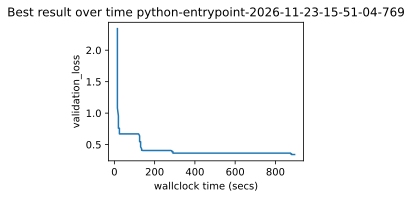

In [9]:
d2l.set_figsize()
e = load_experiment(tuner.name)
e.plot()

<!-- d2l:prose id=sh-async-md-8 fw=all -->

## Visualize the Optimization Process

Once more, we visualize the learning curves of every trial, in terms of the validation error (each color in the plot represents a trial). Compare this to
asynchronous random search in that section. As we have seen for
successive halving in that section, many of the trials are stopped
early, at or shortly after a rung level ($r_{\mathrm{min}}$, $\eta r_{\mathrm{min}}$, $\ldots$). However, trials do not stop
at the same point, because they require different amount of time per epoch. If
we ran standard successive halving instead of ASHA, we would need to synchronize
our workers, before we can promote configurations to the next rung level.

Text(0, 0.5, 'validation error')

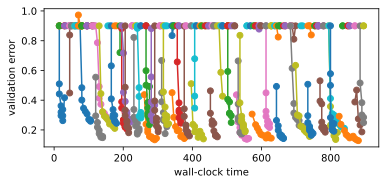

In [10]:
d2l.set_figsize([6, 2.5])
results = e.results
for trial_id in results.trial_id.unique():
    df = results[results["trial_id"] == trial_id]
    d2l.plt.plot(
        df["st_tuner_time"],
        df["validation_error"],
        marker="o"
    )
d2l.plt.xlabel("wall-clock time")
d2l.plt.ylabel("validation error")

<!-- d2l:prose id=sh-async-md-9 fw=all -->

## Summary

Compared to random search, successive halving is not quite as trivial to run in
an asynchronous distributed setting. To avoid synchronization points, we promote
configurations as quickly as possible to the next rung level, even if this means
promoting some wrong ones. In practice, this usually does not hurt much, and the
gains of asynchronous versus synchronous scheduling are usually much higher
than the loss of the suboptimal decision making.

## Exercises

1. One round of synchronous successive halving with $N = \eta^K$ configurations and $r_{\mathrm{max}} = r_{\mathrm{min}}\eta^K$ trains for $(K+1)r_{\mathrm{max}}$ epochs when every promoted trial restarts from scratch, as in that section.
    1. Show that the round trains for $r_{\mathrm{max}}(1 + K(1 - 1/\eta))$ epochs if promoted trials resume from a checkpoint instead, and that restarting costs at most a factor $\eta/(\eta - 1)$ more.
    2. In the stopping variant that the code in this section runs, every trial starts with `max_epochs` equal to $r_{\mathrm{max}}$, and at rung $r_j$ Syne Tune lets the best fraction $r_j/r_{j+1}$ of the trials continue, where $r_{j+1}$ is the next rung level or $r_{\mathrm{max}}$. Assume that exactly these fractions continue. Show that a fraction $r_{\mathrm{min}}/r_j$ of all trials reaches $r_j$, and compute the expected number of epochs per trial for the rung levels 2, 4 and 8 and $r_{\mathrm{max}} = 10$.
    3. How many times as many trials should ASHA then start in 15 minutes as asynchronous random search in that section, which trains every trial for 10 epochs? Compare with the numbers of trials in the two runs, and name a cost that the count of epochs leaves out.
2. In the promotion variant of ASHA described at the start of this section, a trial at a rung is promoted once it is among the best $\lfloor m/\eta \rfloor$ of the $m$ results at that rung and has not been promoted before. Let $r_{\mathrm{max}} = r_{\mathrm{min}}\eta^K$.
    1. Show that at least $\eta^K$ trials must finish at rung $r_{\mathrm{min}}$ before any trial reaches $r_{\mathrm{max}}$, as in synchronous successive halving.
    2. In the stopping variant that the code runs, the first trial to reach a rung always continues, since a single recorded value does not determine a cutoff. How many trials must finish at $r_{\mathrm{min}}$ before the first trial can reach $r_{\mathrm{max}}$?
    3. What do the two answers imply for the incumbent trajectory early in a run?
3. Asynchronous decisions are based on the results that have arrived so far. Assume that the metric values of the trials at a rung are independent draws from a continuous distribution, as the validation losses are, and arrive in random order.
    1. In the promotion variant, the first promotion from a rung promotes the best of the first $\eta$ results. Show that, for a large rung, this trial belongs to the best fraction $1/\eta$ of all trials at the rung with probability $1-(1-1/\eta)^\eta$. Evaluate this probability for $\eta = 2, 3, 4$ and find its limit as $\eta \to \infty$.
    2. In the stopping variant, the $k$-th trial to reach rung $r_j$ continues if its validation loss is at most `np.quantile(values, q)`, where `values` holds the $k$ losses recorded at the rung so far, its own included, and $q = r_j/r_{j+1}$. Show that it continues with probability $(\lfloor (k-1)q \rfloor + 1)/k$, and evaluate this for $q = 1/2$ and $k = 1, \ldots, 5$. Which trials of a run benefit from this?
    3. From `e.results`, compute for each of the rung levels 2, 4 and 8 the fraction of the trials that reached the rung and were not stopped there, leaving out trials that were still running when the time limit was reached. Count a trial as stopped at rung $r_j$ if its last reported epoch lies between $r_j$ and the next rung level, since a stop decision can arrive an epoch late. Compare the fractions with $r_j/r_{j+1}$.
4. The text argues that the early decisions of ASHA do little harm because the ranking of configurations is often consistent across rung levels. Test this claim with the learning curves of asynchronous random search in that section, where every trial was trained for 10 epochs and reported its validation error after every epoch. Load these results with `load_experiment` and the name of that tuning run.
    1. For the trials that completed 10 epochs, compute the Spearman rank correlation (`scipy.stats.spearmanr`) between the errors after 2 and after 10 epochs, and between the errors after 4 and after 10 epochs.
    2. Replay these trials, in the order in which they reached each rung, through the stopping rule of this section's run, applied to the validation error, the only metric that run recorded: rung levels 2, 4 and 8, continuation fractions $1/2$, $1/2$ and $4/5$, the first trial at a rung always continues, and a trial whose error equals the cutoff continues. Ignore that stopping a trial would have changed the timing of later trials. How many of the trials whose error after 10 epochs lies within 0.02 of the best would have been stopped, and at which rungs?
    3. Repeat the replay with `grace_period=4`, which gives the rung levels 4 and 8 with continuation fractions $1/2$ and $4/5$. Report the number of epochs that each replay trains and whether the best trial survives.
5. Implement the promotion variant of ASHA in the API of that section, as a subclass `ASHAScheduler` of `d2l.HPOScheduler` with the arguments `searcher`, `eta`, `r_min` and `r_max` and the rung levels of `d2l.SuccessiveHalvingScheduler`. Its `update` records each result at its rung. Its `suggest` scans the rungs from the top down and returns the first configuration that is among the best $\lfloor m/\eta \rfloor$ of the $m$ results at its rung and has not been promoted yet, with `max_epochs` set to the next rung level. If there is no such configuration, it returns a new one at $r_{\mathrm{min}}$.
    1. Test the scheduler with `d2l.HPOTuner`, `d2l.RandomSearcher` and the configuration space of that section, on a synthetic objective that returns at once: an error that depends on `learning_rate`, decreases with `max_epochs`, and carries a little noise.
    2. Run `ASHAScheduler` and `d2l.SuccessiveHalvingScheduler` for 60 trials each on this objective, with $r_{\mathrm{min}} = 2$, $\eta = 2$ and $r_{\mathrm{max}} = 10$. Report the number of trials that each scheduler evaluates at every rung, the trial at which each first evaluates a configuration at $r_{\mathrm{max}}$, and the noise-free error of the best configuration that each evaluates at $r_{\mathrm{max}}$.

<!-- d2l:prose id=sh-async-md-10 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/12101)